In [35]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from google.colab.patches import cv2_imshow


array([[[ 61,  47,  35],
        [ 62,  46,  34],
        [ 62,  46,  34],
        ...,
        [ 73,  57,  40],
        [ 72,  56,  39],
        [ 73,  57,  37]],

       [[ 61,  47,  35],
        [ 62,  46,  34],
        [ 62,  46,  34],
        ...,
        [ 74,  58,  41],
        [ 72,  56,  39],
        [ 73,  57,  39]],

       [[ 62,  48,  36],
        [ 61,  47,  35],
        [ 61,  46,  34],
        ...,
        [ 74,  58,  41],
        [ 74,  58,  41],
        [ 73,  57,  41]],

       ...,

       [[ 42,  42,  37],
        [ 42,  42,  37],
        [ 42,  42,  37],
        ...,
        [146, 163,   0],
        [146, 163,   0],
        [146, 163,   0]],

       [[ 42,  42,  37],
        [ 42,  42,  37],
        [ 42,  42,  37],
        ...,
        [146, 163,   0],
        [146, 163,   0],
        [146, 163,   0]],

       [[ 42,  42,  37],
        [ 42,  42,  37],
        [ 42,  42,  37],
        ...,
        [146, 163,   0],
        [146, 163,   0],
        [146, 163,   0]]], dtype=uint8)
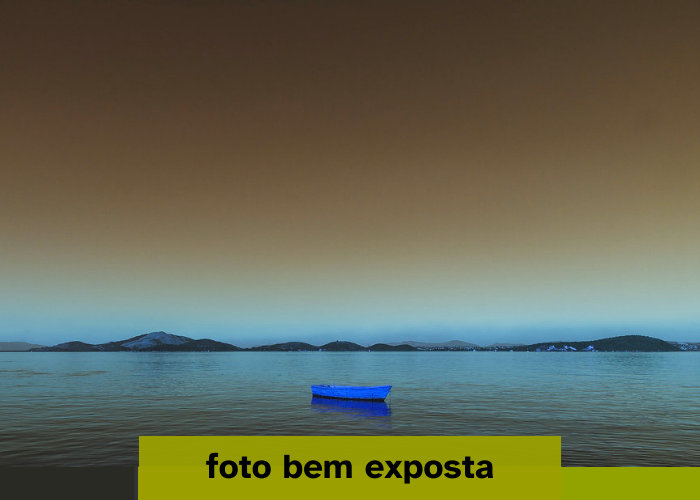

In [ ]:
img_foto_exposta = cv2.imread('/content/exposicao-bem-exposta.png') 
img_foto_exposta

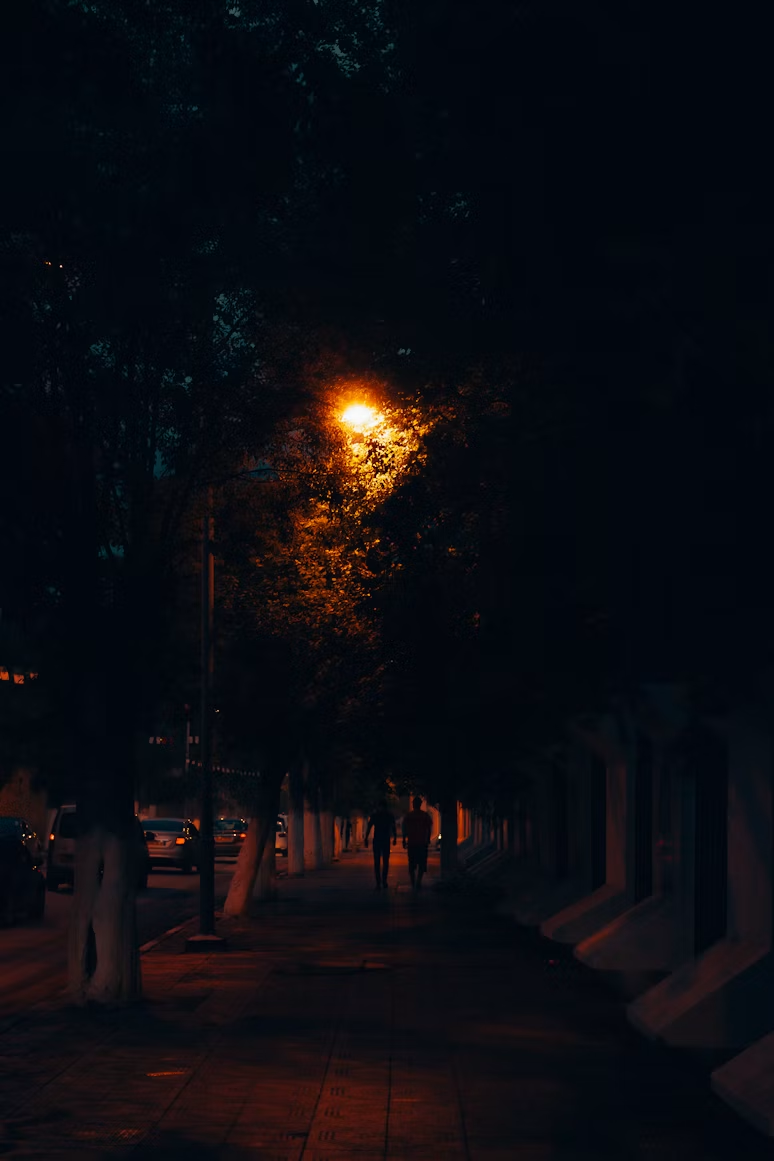

In [ ]:
img_foto_escura = cv2.imread('/content/foto-escura.png')
cv2_imshow(img_foto_escura)

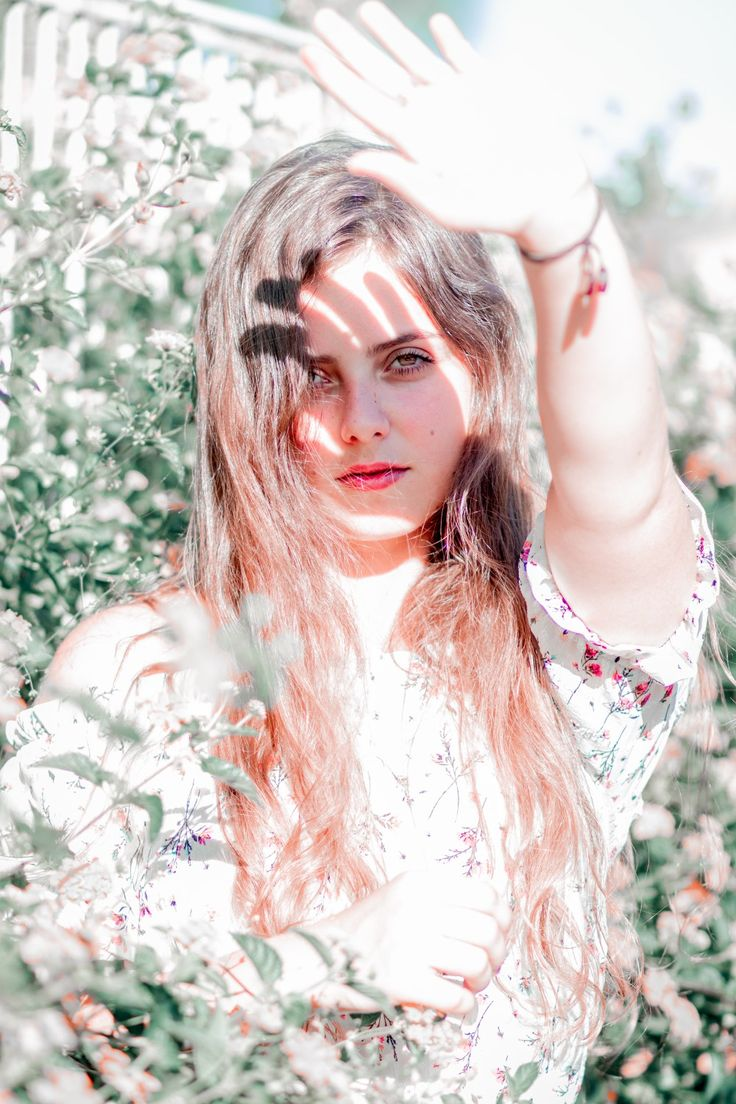

In [38]:
img_foto_clara = cv2.imread('/content/foto-estourada.png')
cv2_imshow(img_foto_clara)

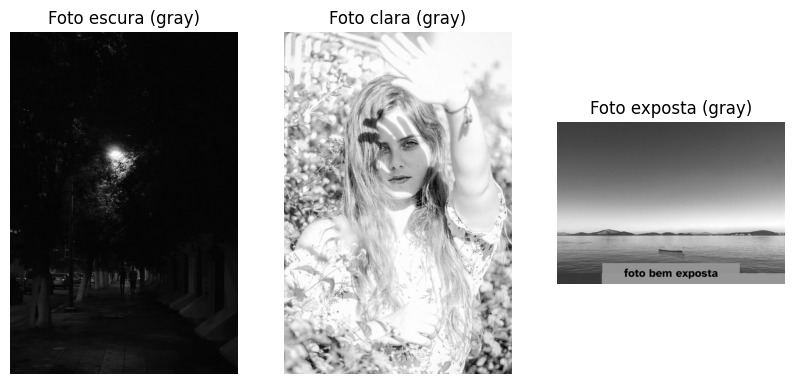

In [39]:
img_escura_gray = cv2.cvtColor(img_foto_escura, cv2.COLOR_BGR2GRAY)
img_clara_gray = cv2.cvtColor(img_foto_clara, cv2.COLOR_BGR2GRAY)
img_exposta_gray = cv2.cvtColor(img_foto_exposta, cv2.COLOR_BGR2GRAY)

# Exibir as imagens em tons de cinza
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
axes[0].imshow(img_escura_gray, cmap='gray')
axes[0].set_title('Foto escura (gray)')
axes[0].axis('off')

axes[1].imshow(img_clara_gray, cmap='gray')
axes[1].set_title('Foto clara (gray)')
axes[1].axis('off')

axes[2].imshow(img_exposta_gray, cmap='gray')
axes[2].set_title('Foto exposta (gray)')
axes[2].axis('off')


plt.show()

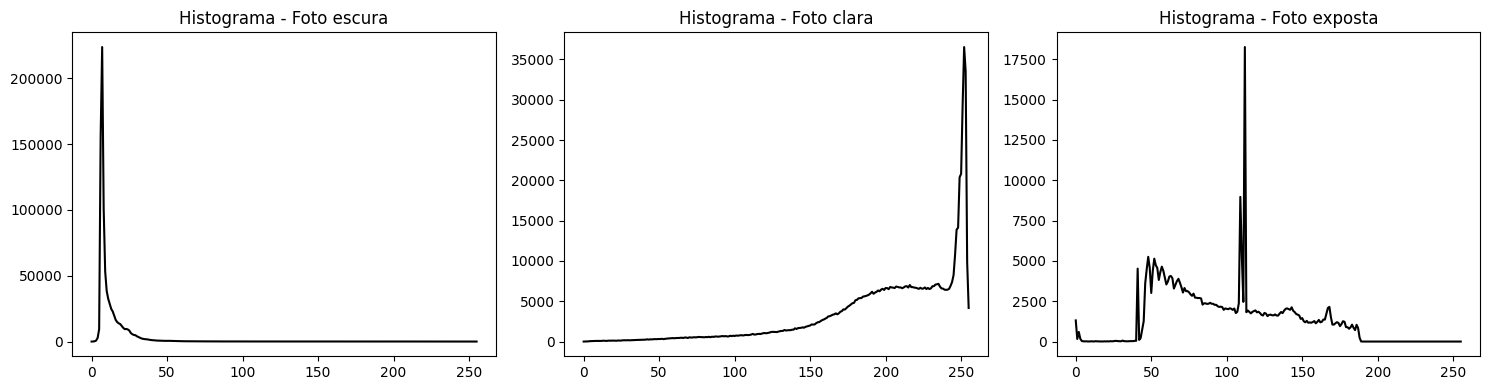

In [40]:
hist_escura = cv2.calcHist([img_escura_gray], [0], None, [256], [0, 256])
hist_clara = cv2.calcHist([img_clara_gray], [0], None, [256], [0, 256])
hist_exposta = cv2.calcHist([img_exposta_gray], [0], None, [256], [0, 256])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(hist_escura, color='black')
axes[0].set_title('Histograma - Foto escura')

axes[1].plot(hist_clara, color='black')
axes[1].set_title('Histograma - Foto clara')

axes[2].plot(hist_exposta, color='black')
axes[2].set_title('Histograma - Foto exposta')

plt.tight_layout()
plt.show()



1.   Foto escura: Pico entre 0 e 10. Praticamente toda a imagem está nas sombras mais profundas, o que confirma subexposição severa
2.   pico bem acentuado em 255 (o valor máximo). Esse acúmulo no extremo direito é clipping/estouro de highlights — grande parte da imagem saturou no branco, perdendo detalhe nas áreas mais claras
3. Aqui a distribuição é bem mais espalhada, concentrada entre 40 e 190, com dois picos (perto de 50 e perto de 110) mas sem acúmulo nos extremos.



Foto escura: expansão de contraste. Utiliza valores mínimos e máximos para esticar a faixa de nível de cinza da imagem. Muito usada para corrigir imagens de baixo contraste.

In [41]:
def expansao_contraste_pixel_a_pixel(imagem):
    """
    Aplica expansão de contraste percorrendo a imagem pixel a pixel.

    O menor valor da imagem é mapeado para 0
    e o maior valor é mapeado para 255.
    """
    L = imagem.min()
    H = imagem.max()

    if H == L:
        return imagem.copy()

    resultado = np.zeros_like(imagem)

    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            resultado[i, j] = (
                (imagem[i, j] - L) * 255 / (H - L)
            )

    return resultado.astype(np.uint8)


def expansao_contraste_numpy(imagem):
    """
    Aplica expansão de contraste usando operações vetorizadas do NumPy.
    """
    L = imagem.min()
    H = imagem.max()

    if H == L:
        return imagem.copy()

    resultado = (imagem.astype(float) - L) * 255 / (H - L)

    return resultado.astype(np.uint8)


In [42]:
img_escura_stretch = expansao_contraste_numpy(img_escura_gray)

L = img_escura_gray.min()
H = img_escura_gray.max()
print(f"L = {L}, H = {H}")

L = 1, H = 253


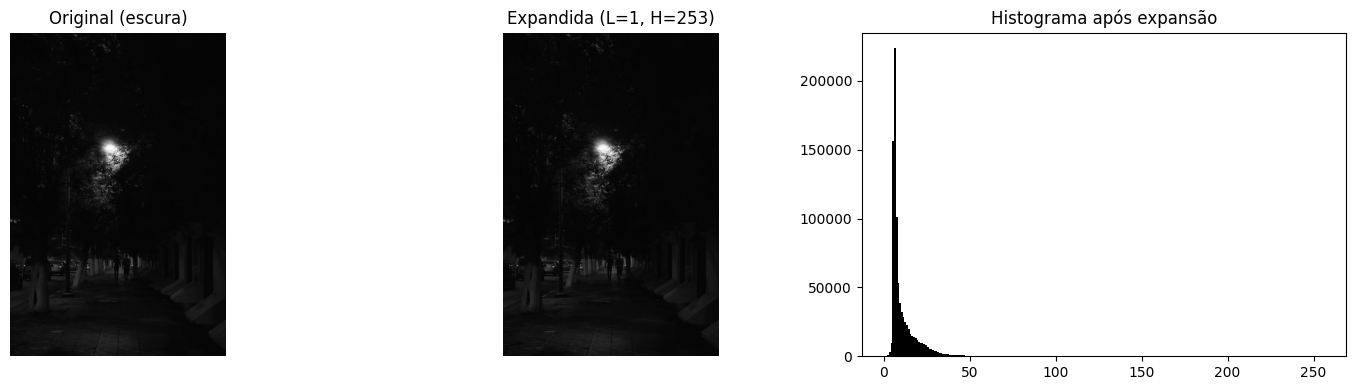

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(img_escura_gray, cmap='gray')
axes[0].set_title('Original (escura)')
axes[0].axis('off')

axes[1].imshow(img_escura_stretch, cmap='gray')
axes[1].set_title(f'Expandida (L={L}, H={H})')
axes[1].axis('off')

axes[2].hist(img_escura_stretch.ravel(), bins=256, range=(0, 256), color='black')
axes[2].set_title('Histograma após expansão')

plt.tight_layout()
plt.show()

Foto exposta: equalização de histograma. Redistribui os níveis de intensidade para que todas as faixas tenham uma frequência de pixels mais uniforme. Revela detalhes ocultos em sombras profundas ou áreas de alto/baixo brilh

In [44]:
def equalizacao_histograma_manual(imagem):
    """
    Equaliza o histograma manualmente.

    Espera uma imagem em tons de cinza (uint8).
    """
    histograma = np.zeros(256, dtype=int)

    # Calcula o histograma
    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            nivel = imagem[i, j]
            histograma[nivel] += 1

    # Calcula a distribuição acumulada (CDF)
    cdf = np.cumsum(histograma)

    # Normaliza a CDF para o intervalo [0, 255]
    cdf_normalizada = 255 * cdf / cdf[-1]

    resultado = np.zeros_like(imagem)

    # Substitui cada pixel pelo novo nível de cinza
    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            resultado[i, j] = cdf_normalizada[imagem[i, j]]

    return resultado.astype(np.uint8)


def equalizacao_histograma_opencv(imagem):
    """
    Equaliza o histograma usando a função pronta do OpenCV.
    """
    return cv2.equalizeHist(imagem)


In [45]:
img_exposta_eq_manual = equalizacao_histograma_manual(img_exposta_gray)
img_exposta_eq_opencv = equalizacao_histograma_opencv(img_exposta_gray)

In [46]:
diferenca = np.abs(img_exposta_eq_manual.astype(int) - img_exposta_eq_opencv.astype(int))
print(f"Diferença máxima entre manual e OpenCV: {diferenca.max()}")

Diferença máxima entre manual e OpenCV: 1


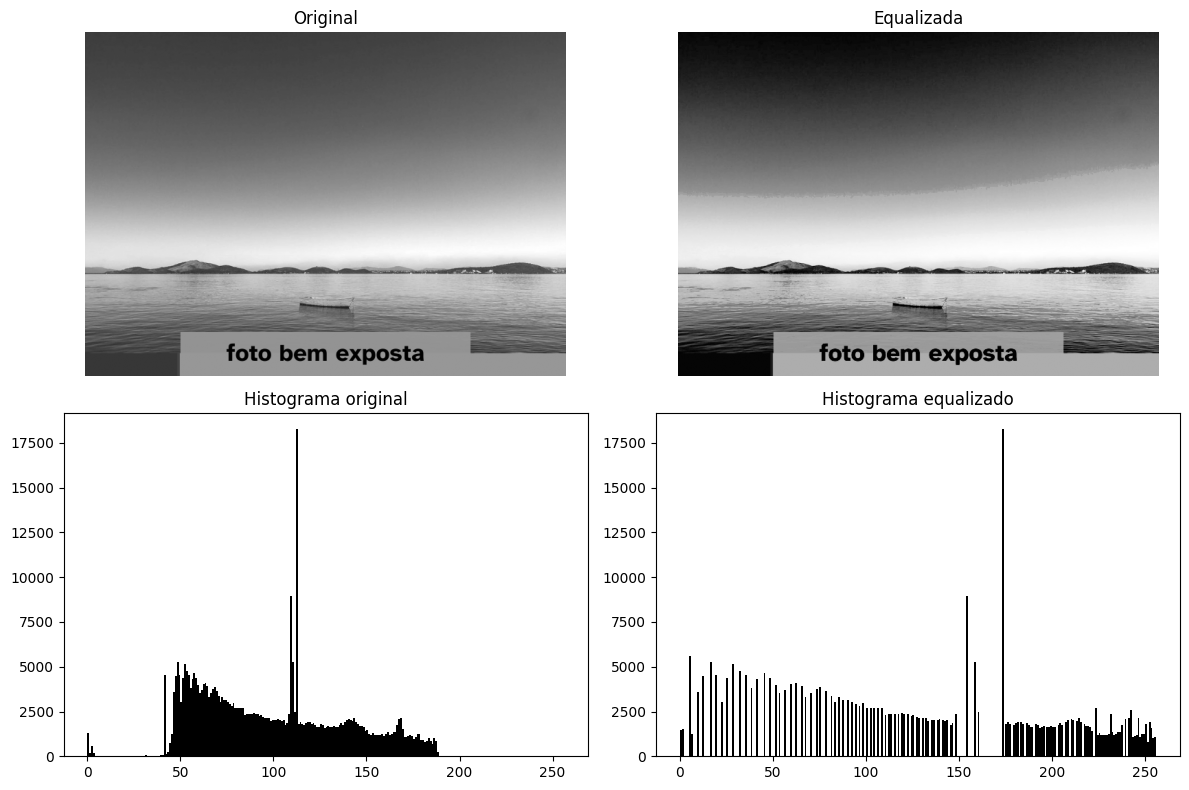

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].imshow(img_exposta_gray, cmap='gray')
axes[0,0].set_title('Original')
axes[0,0].axis('off')

axes[0,1].imshow(img_exposta_eq_opencv, cmap='gray')
axes[0,1].set_title('Equalizada')
axes[0,1].axis('off')

axes[1,0].hist(img_exposta_gray.ravel(), bins=256, range=(0,256), color='black')
axes[1,0].set_title('Histograma original')

axes[1,1].hist(img_exposta_eq_opencv.ravel(), bins=256, range=(0,256), color='black')
axes[1,1].set_title('Histograma equalizado')

plt.tight_layout()
plt.show()

Foto clara: correção gamma. É uma função não linear que corrige resposta de luminosidade de monitores ou ajusta  o brilho de áreas intermediárias (médios-tons) sem perder os contrastes de preto e branco.

In [48]:


def correcao_gamma_pixel_a_pixel(imagem, gamma):
    """
    Aplica correção de gamma percorrendo a imagem pixel a pixel.

    gamma < 1  -> clareia a imagem
    gamma > 1  -> escurece a imagem
    gamma = 1  -> mantém a imagem
    """
    if gamma <= 0:
        raise ValueError("O valor de gamma deve ser maior que zero.")

    resultado = np.zeros_like(imagem)

    for i in range(imagem.shape[0]):
        for j in range(imagem.shape[1]):
            r = imagem[i, j] / 255.0
            resultado[i, j] = 255 * (r ** gamma)

    return resultado.astype(np.uint8)


def correcao_gamma_numpy(imagem, gamma):
    """
    Aplica correção de gamma usando operações vetorizadas do NumPy.
    """
    if gamma <= 0:
        raise ValueError("O valor de gamma deve ser maior que zero.")

    imagem_normalizada = imagem / 255.0
    resultado = 255 * (imagem_normalizada ** gamma)

    return resultado.astype(np.uint8)


In [49]:
gamma = 2.2
img_clara_gamma = correcao_gamma_numpy(img_clara_gray, gamma)

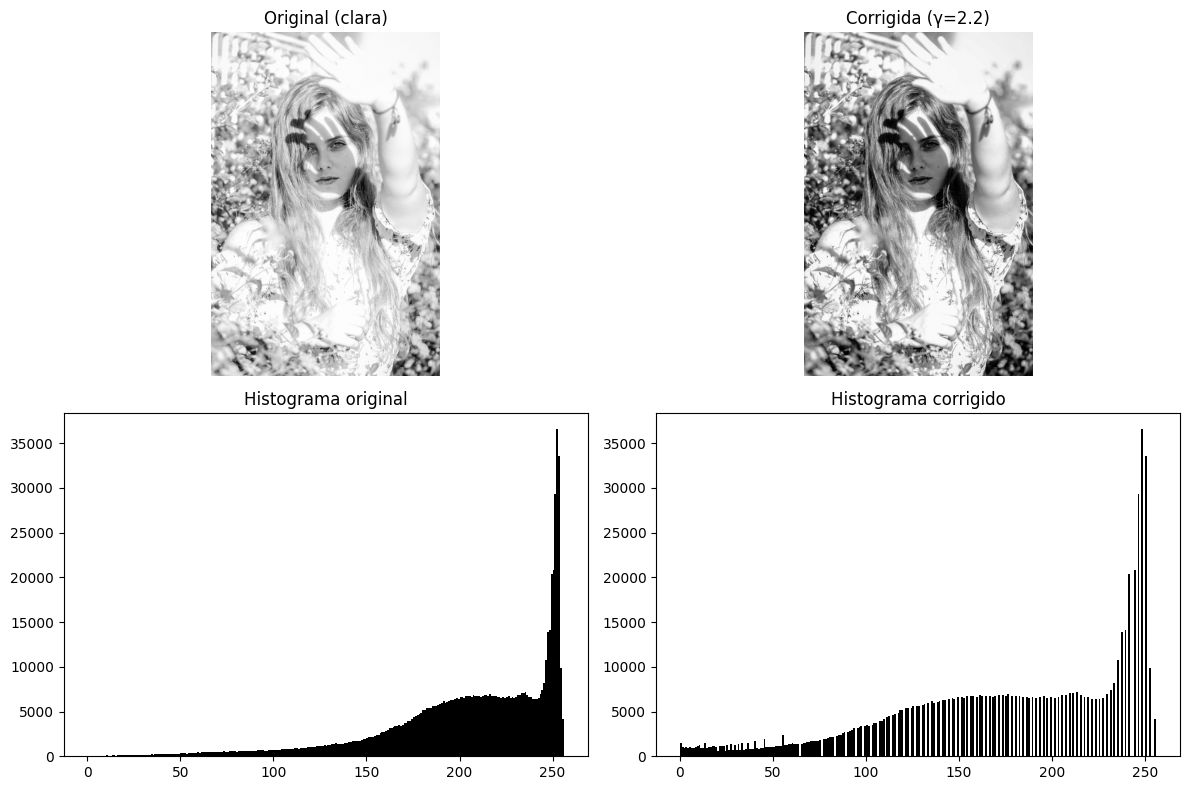

In [50]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0,0].imshow(img_clara_gray, cmap='gray')
axes[0,0].set_title('Original (clara)')
axes[0,0].axis('off')

axes[0,1].imshow(img_clara_gamma, cmap='gray')
axes[0,1].set_title(f'Corrigida (γ={gamma})')
axes[0,1].axis('off')

axes[1,0].hist(img_clara_gray.ravel(), bins=256, range=(0,256), color='black')
axes[1,0].set_title('Histograma original')

axes[1,1].hist(img_clara_gamma.ravel(), bins=256, range=(0,256), color='black')
axes[1,1].set_title('Histograma corrigido')

plt.tight_layout()
plt.show()

In [51]:
img_clara_gamma_manual = correcao_gamma_pixel_a_pixel(img_clara_gray, gamma)
print(np.array_equal(img_clara_gamma, img_clara_gamma_manual))  # deve dar True

True


In [52]:
diff_escura = np.abs(img_escura_gray.astype(int) - img_escura_stretch.astype(int)).mean()
diff_exposta = np.abs(img_exposta_gray.astype(int) - img_exposta_eq_opencv.astype(int)).mean()
diff_clara = np.abs(img_clara_gray.astype(int) - img_clara_gamma.astype(int)).mean()

print(f"Diferença média - escura: {diff_escura:.2f}")
print(f"Diferença média - exposta: {diff_exposta:.2f}")
print(f"Diferença média - clara: {diff_clara:.2f}")

Diferença média - escura: 1.00
Diferença média - exposta: 39.77
Diferença média - clara: 37.63


Podemos observar que a técnica de expansão por contraste foi a menos efetiva. Talvez isso tenha ocorrido pelo pixel extremo encontrado na imagem que foi o 253, muuito claro e brilhante, muito provavelmente oriundo do poste que se encontra na imagem. Todavia, a técnica de correção pega o pixel mais claro de toda a imagem, provavelmente causando essa redistribuição tímida das faixas de cinza devido ao pixel do poste de luz.

novo(x)=(x−1)×
253−1
255
	​

=(x−1)×1,0079

Pode ver na fómula que isso significa que a transformação é quase uma função identidade, cada pixel recebe um valor quase idêntico ao original (só desloca 1 unidade e multiplica por um fator quase imperceptível)